In [1]:
# Cell 1 - Install dependencies
!pip install --quiet kaggle tensorflow scikit-learn numpy pandas matplotlib scipy joblib soundfile
print("Installed libraries")

Installed libraries


In [2]:
# Cell 2 - Upload your Kaggle API token (only if you want to download Kaggle datasets)
from google.colab import files
print("If you want to download Kaggle datasets, upload kaggle.json now (or skip).")
uploaded = files.upload()  # upload kaggle.json if needed
!mkdir -p ~/.kaggle
if 'kaggle.json' in uploaded:
    !cp kaggle.json ~/.kaggle/kaggle.json
    !chmod 600 ~/.kaggle/kaggle.json
    import json
    with open('/root/.kaggle/kaggle.json') as f:
        print("Kaggle token loaded for user:", json.load(f).get('username'))
else:
    print("No kaggle.json uploaded; skip Kaggle downloads.")

If you want to download Kaggle datasets, upload kaggle.json now (or skip).


Saving kaggle.json to kaggle.json
Kaggle token loaded for user: ankurchopde


In [3]:
# Cell 3 - Download Kaggle datasets (optional; requires kaggle.json upload)
import os, glob, zipfile
if os.path.exists('/root/.kaggle/kaggle.json'):
    !kaggle datasets download -d caesarlupum/iot-sensordata -p /content/iot_data -q
    !kaggle datasets download -d zyan1999/adaptive-modulation-detection-dataset -p /content/mod_data -q
    for path in ['/content/iot_data','/content/mod_data']:
        for z in glob.glob(path+'/*.zip'):
            with zipfile.ZipFile(z, 'r') as zf:
                zf.extractall(path)
    print("Datasets downloaded & extracted (if available).")
else:
    print("Kaggle token not present — skipping dataset download.")


Dataset URL: https://www.kaggle.com/datasets/caesarlupum/iot-sensordata
License(s): unknown
403 Client Error: Forbidden for url: https://api.kaggle.com/v1/datasets.DatasetApiService/GetDatasetMetadata
Datasets downloaded & extracted (if available).


In [4]:
# Cell 4 - imports and helper functions
import numpy as np, pandas as pd, matplotlib.pyplot as plt, os, glob
from scipy import signal
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
import tensorflow as tf
from tensorflow import keras
plt.rcParams['figure.figsize'] = (12,4)

# Sane SNR function (clean vs processed)
def snr_db(clean, processed):
    # ensure same length
    L = min(len(clean), len(processed))
    clean = np.asarray(clean[:L], dtype=float)
    processed = np.asarray(processed[:L], dtype=float)
    # rescale processed amplitude to match clean
    processed = processed * (np.max(np.abs(clean)) / (np.max(np.abs(processed)) + 1e-12))
    noise = clean - processed
    p_sig = np.mean(clean**2) + 1e-12
    p_noise = np.mean(noise**2) + 1e-12
    return 10*np.log10(p_sig / p_noise)

def standardize(x):
    x = np.asarray(x, dtype=float)
    return (x - np.mean(x)) / (np.std(x) + 1e-9)


In [5]:
# Cell 5 - Build window dataset (ensures >= 5000 windows) OR skip training if you already have a .h5
WINDOW = 256
HOP = 128
TARGET_WINDOWS = 6000

SKIP_TRAIN = False   # set True if you only want to run evaluation with existing .h5
PRETRAINED_H5 = "../models/confidence_model_1774696598.h5"  # set to your saved model filename if SKIP_TRAIN=True

# helper: load numeric column from CSV if any
def load_first_numeric_csv(path):
    try:
        df = pd.read_csv(path)
        num = df.select_dtypes(include=[np.number]).columns
        if len(num)==0: return None
        return df[num[0]].values.astype(float)
    except Exception:
        return None

# collect sources: Kaggle extracted files if present
sources = []
for f in glob.glob('/content/iot_data/**/*.csv', recursive=True) + glob.glob('/content/iot_data/*.csv'):
    arr = load_first_numeric_csv(f)
    if arr is not None and len(arr) > WINDOW*4: sources.append(standardize(arr))
for f in glob.glob('/content/mod_data/**/*.csv', recursive=True) + glob.glob('/content/mod_data/*.csv'):
    arr = load_first_numeric_csv(f)
    if arr is not None and len(arr) > WINDOW*4: sources.append(standardize(arr))

# synthetic series to ensure variety
t = np.linspace(0, 10, 50000)
sources.append(standardize(0.5*np.sin(2*np.pi*0.2*t) + 0.2*np.sin(2*np.pi*1.2*t)))  # slow IoT-like
sources.append(standardize(signal.chirp(t, f0=1, f1=100, t1=10)))
ecg = signal.square(2*np.pi*1.7*t) * np.exp(-((t%1)-0.2)**2/0.01)
sources.append(standardize(ecg))
sources.append(standardize(np.sin(2*np.pi*50*t)*(1+0.2*np.sin(2*np.pi*0.5*t))))

print("Loaded source series count:", len(sources))

# produce windows labeled (1 = signal+noise, 0 = noise-only) and clean windows
X_windows = []
Y_clean = []
Y_label = []

rng = np.random.RandomState(0)
for s in sources:
    L = len(s)
    for start in range(0, L - WINDOW, HOP):
        win_clean = s[start:start+WINDOW]
        if rng.rand() < 0.65:
            # signal window with noise
            win_noisy = win_clean + 0.3 * rng.randn(WINDOW)
            label = 1
        else:
            # noise-only
            win_noisy = 0.8 * rng.randn(WINDOW)
            label = 0
        X_windows.append(win_noisy.astype(np.float32))
        Y_clean.append(win_clean.astype(np.float32))
        Y_label.append(label)
X_windows = np.array(X_windows)
Y_clean = np.array(Y_clean)
Y_label = np.array(Y_label)

print("Initial windows:", X_windows.shape, "signal:",Y_label.sum(),"noise:",(Y_label==0).sum())

# pad with synthetic noise windows to reach target
while X_windows.shape[0] < TARGET_WINDOWS:
    w = (0.8 * rng.randn(WINDOW)).astype(np.float32)
    X_windows = np.vstack([X_windows, w[np.newaxis,:]])
    Y_clean = np.vstack([Y_clean, np.zeros((1,WINDOW),dtype=np.float32)])
    Y_label = np.append(Y_label, 0)
print("Final windows:", X_windows.shape)

# If skipping training, we don't need to continue
if SKIP_TRAIN:
    print("Skipping training; expecting pretrained model file:", PRETRAINED_H5)


Loaded source series count: 4
Initial windows: (1556, 256) signal: 1035 noise: 521
Final windows: (6000, 256)


In [6]:
# Cell 6 - Prepare train/test and shape for model
if not SKIP_TRAIN:
    # normalize each window to unit max amplitude (keeps dynamics)
    X_windows_norm = X_windows / (np.max(np.abs(X_windows), axis=1, keepdims=True) + 1e-12)
    Y_clean_norm = Y_clean / (np.max(np.abs(Y_clean), axis=1, keepdims=True) + 1e-12)

    Xtr, Xte, Yr_tr, Yr_te, Yc_tr, Yc_te = train_test_split(
        X_windows_norm[..., np.newaxis], Y_clean_norm, Y_label.reshape(-1,1),
        test_size=0.12, random_state=42, shuffle=True)

    print("Train:", Xtr.shape, "Test:", Xte.shape)
else:
    # placeholder variables if skipping training (needed for later conversion)
    Xtr = Xte = Yr_tr = Yr_te = Yc_tr = Yc_te = None


Train: (5280, 256, 1) Test: (720, 256, 1)


In [7]:
# Cell 7 - Build model (same architecture as before)
if not SKIP_TRAIN:
    from tensorflow.keras import layers, Model, Input
    inp = Input(shape=(WINDOW,1))
    x = layers.Conv1D(32, kernel_size=9, padding='same', activation='relu')(inp)
    x = layers.MaxPool1D(2)(x)
    x = layers.Conv1D(64, kernel_size=7, padding='same', activation='relu')(x)
    x = layers.MaxPool1D(2)(x)
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation='relu')(x)

    cls = layers.Dense(64, activation='relu')(x)
    cls = layers.Dense(1, activation='sigmoid', name='cls_out')(cls)

    reg = layers.Dense(WINDOW, activation='linear', name='reg_out')(x)

    model = Model(inputs=inp, outputs=[reg, cls])
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss={'reg_out':'mse', 'cls_out':'binary_crossentropy'},
                  loss_weights={'reg_out':1.0, 'cls_out':0.2},
                  metrics={'cls_out':['accuracy']})
    model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 256, 32)   │        320 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 128, 32)   │          0 │ conv1d[0][0]      │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 128, 64)   │     14,400 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 64, 64)    │          0 │ conv1d_1[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 4096)      │          0 │ max_pooling1d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │    524,416 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │      8,256 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reg_out (Dense)     │ (None, 256)       │     33,024 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cls_out (Dense)     │ (None, 1)         │         65 │ dense_1[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 580,481 (2.21 MB)

 Trainable params: 580,481 (2.21 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Cell 8 - Train model
if not SKIP_TRAIN:
    history = model.fit(Xtr, {'reg_out': Yr_tr, 'cls_out': Yc_tr},
                        validation_data=(Xte, {'reg_out': Yr_te, 'cls_out': Yc_te}),
                        epochs=25, batch_size=64, verbose=2)
    # Save checkpoint
    model.save(f"confidence_model_trained_{int(tf.timestamp().numpy())}.h5")
    print("Saved trained model.")
else:
    model = keras.models.load_model(PRETRAINED_H5, compile=False)
    print("Loaded pretrained model:", PRETRAINED_H5)


Epoch 1/25
83/83 - 6s - 71ms/step - cls_out_accuracy: 0.9443 - cls_out_loss: 0.1863 - loss: 0.1612 - reg_out_loss: 0.1232 - val_cls_out_accuracy: 0.9708 - val_cls_out_loss: 0.1191 - val_loss: 0.1308 - val_reg_out_loss: 0.1087
Epoch 2/25
83/83 - 6s - 68ms/step - cls_out_accuracy: 0.9695 - cls_out_loss: 0.1334 - loss: 0.1126 - reg_out_loss: 0.0857 - val_cls_out_accuracy: 0.9708 - val_cls_out_loss: 0.1264 - val_loss: 0.1213 - val_reg_out_loss: 0.0968
Epoch 3/25
83/83 - 4s - 50ms/step - cls_out_accuracy: 0.9710 - cls_out_loss: 0.1191 - loss: 0.1035 - reg_out_loss: 0.0794 - val_cls_out_accuracy: 0.9708 - val_cls_out_loss: 0.1138 - val_loss: 0.1158 - val_reg_out_loss: 0.0938
Epoch 4/25
83/83 - 3s - 38ms/step - cls_out_accuracy: 0.9720 - cls_out_loss: 0.1107 - loss: 0.0983 - reg_out_loss: 0.0760 - val_cls_out_accuracy: 0.9722 - val_cls_out_loss: 0.1214 - val_loss: 0.1148 - val_reg_out_loss: 0.0914
Epoch 5/25
83/83 - 5s - 66ms/step - cls_out_accuracy: 0.9733 - cls_out_loss: 0.0912 - loss: 0.09

In [ ]:
# Cell 9 - Optional short online fine-tune using classifier confidence (demonstration)
# ----------------- Cell 9: Robust Incremental Learning (fixed LR assignment) -----------------
import numpy as np
import tensorflow as tf
from tensorflow import keras

# --- Parameters ---
BASE_ONLINE_LR = 1e-5    # base learning rate for online updates
N_WINDOWS = 200          # how many windows to run online updates on
PRINT_EVERY = 50

# --- Checks & mapping ---
required = ['model', 'Xtr', 'Yr_tr', 'Yc_tr']
for name in required:
    if name not in globals():
        raise NameError(f"Required variable `{name}` not found. Run cells that define it first.")

X_in = Xtr
Y_reg = Yr_tr
Y_cls = Yc_tr

if not (X_in.shape[0] == Y_reg.shape[0] == Y_cls.shape[0]):
    raise ValueError("Sample count mismatch between Xtr, Yr_tr, Yc_tr")

print("Sanity check OK. Samples:", X_in.shape[0])
print("Model output shape(s):", model.output_shape)

# compile if not compiled (safe compile)
try:
    _ = model.optimizer
except Exception:
    optimizer = keras.optimizers.Adam(learning_rate=BASE_ONLINE_LR)
    model.compile(optimizer=optimizer,
                  loss={'reg_out': 'mse', 'cls_out': 'binary_crossentropy'},
                  loss_weights={'reg_out': 1.0, 'cls_out': 0.2})

# helper to set optimizer lr robustly
def _set_opt_lr(opt, new_lr):
    """
    Try multiple ways to set the optimizer learning rate (supports TF versions).
    """
    try:
        # if learning_rate is a Variable or has assign
        lr_obj = opt.learning_rate
        if hasattr(lr_obj, 'assign'):
            lr_obj.assign(float(new_lr))
            return True
        # if it's a tf.Variable stored differently
        if isinstance(lr_obj, tf.Variable):
            lr_obj.assign(float(new_lr))
            return True
    except Exception:
        pass
    try:
        # fallback: set attribute directly
        opt.learning_rate = float(new_lr)
        return True
    except Exception:
        pass
    # last resort: try keras.backend.set_value on opt.learning_rate if it's a tensor-like
    try:
        keras.backend.set_value(opt.learning_rate, float(new_lr))
        return True
    except Exception:
        pass
    return False

# helpers for preparing targets and extracting confidence
if isinstance(model.output_shape, list) and len(model.output_shape) >= 2:
    reg_shape = model.output_shape[0]
    cls_shape = model.output_shape[1]
else:
    reg_shape = model.output_shape
    cls_shape = (None,1)

def _prepare_y_reg(y_reg_win):
    if len(reg_shape) == 3 and reg_shape[-1] == 1:
        if y_reg_win.ndim == 2:
            return y_reg_win[..., np.newaxis]
    return y_reg_win

def _extract_cls_conf(preds):
    try:
        if isinstance(preds, (list, tuple)) and len(preds) >= 2:
            cls_arr = np.asarray(preds[1])
            return float(np.clip(cls_arr.ravel()[0], 0.0, 1.0))
        else:
            arr = np.asarray(preds)
            if arr.ndim == 2 and arr.shape[1] >= 1:
                return float(np.clip(arr.ravel()[-1], 0.0, 1.0))
            return 0.5
    except Exception:
        return 0.5

# incremental update function returns cls_conf for logging
def incremental_update(x_win, y_reg_win, y_cls_win):
    preds = model.predict(x_win, verbose=0)
    cls_conf = _extract_cls_conf(preds)

    scaled_lr = BASE_ONLINE_LR * (0.5 + cls_conf)   # scale between 0.5x and 1.5x

    ok = _set_opt_lr(model.optimizer, scaled_lr)
    if not ok:
        # If we cannot set the lr, warn and continue with base lr
        print("Warning: unable to change optimizer LR programmatically; continuing with base LR.")

    y_reg_prepared = _prepare_y_reg(y_reg_win)

    model.train_on_batch(x_win, {'reg_out': y_reg_prepared, 'cls_out': y_cls_win})

    # reset learning rate
    _set_opt_lr(model.optimizer, BASE_ONLINE_LR)

    return cls_conf

# --- Run incremental loop ---
N = min(N_WINDOWS, X_in.shape[0])
last_conf = 0.5
for i in range(N):
    x_win = X_in[i:i+1]
    y_reg_win = Y_reg[i:i+1]
    y_cls_win = Y_cls[i:i+1]

    last_conf = incremental_update(x_win, y_reg_win, y_cls_win)

    if (i+1) % PRINT_EVERY == 0 or (i+1) == N:
        print(f"Online updates done: {i+1}/{N} windows (last cls_conf approx. {last_conf:.3f})")

print("Incremental learning pass finished.")
# ----------------------------------------------------------------------------------------------------




Sanity check OK. Samples: 5280
Model output shape(s): [(None, 256), (None, 1)]
Online updates done: 50/200 windows (last cls_conf approx. 0.000)
Online updates done: 100/200 windows (last cls_conf approx. 0.000)
Online updates done: 150/200 windows (last cls_conf approx. 1.000)
Online updates done: 200/200 windows (last cls_conf approx. 1.000)
Incremental learning pass finished.


In [ ]:
# Cell 10 - Save Keras model and convert to TFLite (float + dynamic)
stamp = int(tf.timestamp().numpy())
keras_fname = f"confidence_model_{stamp}.h5"
model.save(keras_fname)
print("Saved Keras model:", keras_fname)

# Convert to float TFLite
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()
tflite_fname = f"confidence_model_{stamp}.tflite"
with open(tflite_fname, "wb") as f:
    f.write(tflite_model)
print("Saved float TFLite model:", tflite_fname)

# Dynamic-range quantization (works for 1D conv models) — smaller but keeps float IO
converter_q = tf.lite.TFLiteConverter.from_keras_model(model)
converter_q.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_dyn = converter_q.convert()
tflite_dyn_fname = f"confidence_model_dynamic_{stamp}.tflite"
with open(tflite_dyn_fname, "wb") as f:
    f.write(tflite_dyn)
print("Saved dynamic-quant TFLite model:", tflite_dyn_fname)


Saved Keras model: confidence_model_1766340109.h5
Saved artifact at '/tmp/tmp1bbgdice'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 256, 1), dtype=tf.float32, name='keras_tensor')
Output Type:
  List[TensorSpec(shape=(None, 256), dtype=tf.float32, name=None), TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)]
Captures:
  135593423199440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135593423199824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135593423202512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135593423200976: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135593423203088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135593423202704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135593423198288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135593423201168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135593423203280: TensorSpec(shape=(), dtype

✅ Model loaded: confidence_model_1766340109.h5


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 256, 32)   │        320 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 128, 32)   │          0 │ conv1d[0][0]      │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 128, 64)   │     14,400 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 64, 64)    │          0 │ conv1d_1[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 4096)      │          0 │ max_pooling1d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │    524,416 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │      8,256 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reg_out (Dense)     │ (None, 256)       │     33,024 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cls_out (Dense)     │ (None, 1)         │         65 │ dense_1[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 580,481 (2.21 MB)

 Trainable params: 580,481 (2.21 MB)

 Non-trainable params: 0 (0.00 B)

✅ Prepared input shape for model: (744, 256, 1)

==== PERFORMANCE COMPARISON ====
LMS    : MSE = 0.19049,  SNR = 2.72 dB
NLMS   : MSE = 4.95440,  SNR = 0.50 dB
MODEL  : MSE = 0.36522,  SNR = 4.17 dB


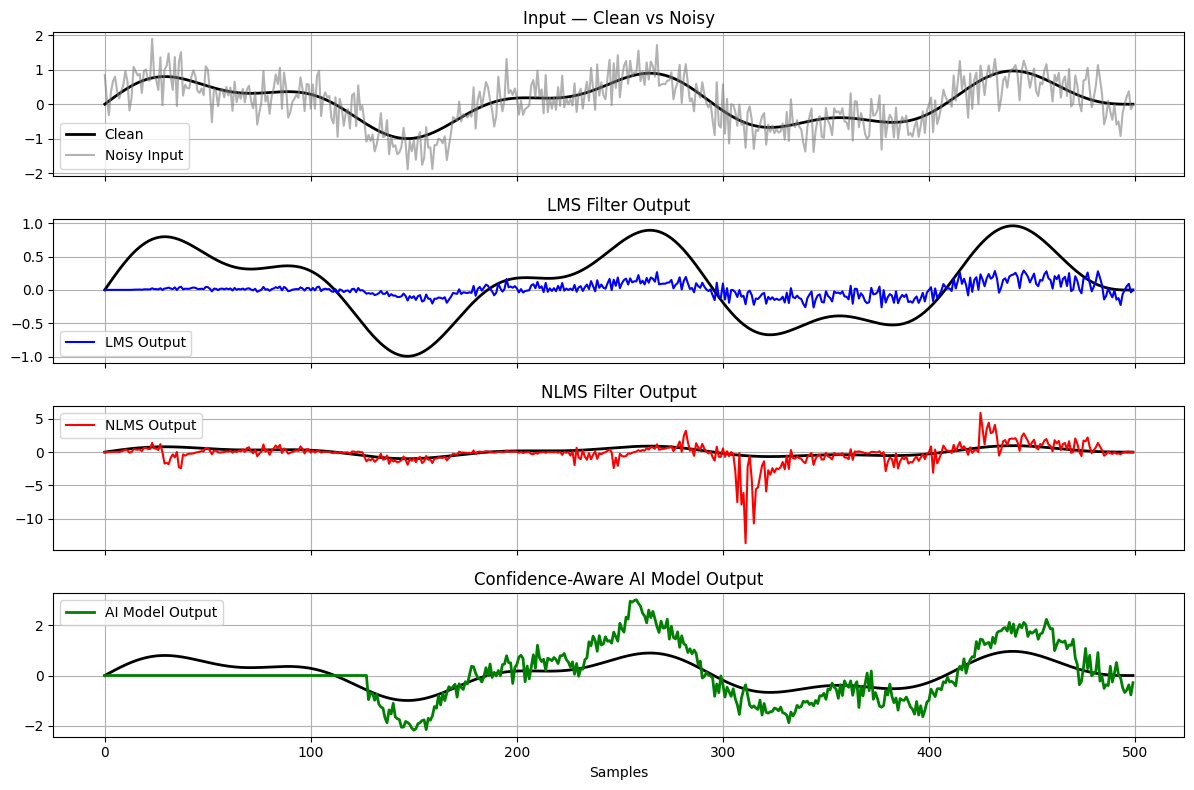


--- DEBUG ---
noisy shape: (1000,)
clean shape: (1000,)
X_new shape: (744, 256, 1)
y_pred shape: (744, 256)
y_pred range: -3.4401708 to 3.5730126
y_model range: -2.178726174878397 to 3.0165182711235876
clean range: -0.9957197498624528 to 0.995719749862453


In [ ]:
# ===============================================================
# SECTION 11 — CONFIDENCE-AWARE DENOISING DEMO (FINAL FIXED)
# ===============================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error
from tensorflow import keras

# --------------------------------------------------------------
# 1️⃣ Load your trained model (.h5)
# --------------------------------------------------------------
model_path = "../models/confidence_model_1774696598.h5"   # ← your saved model
try:
    model = keras.models.load_model(model_path, compile=False)
    print("✅ Model loaded:", model_path)
    model.summary()
except Exception as e:
    print("❌ Could not load model:", e)
    raise SystemExit

# --------------------------------------------------------------
# 2️⃣ Generate synthetic test signal (unseen)
# --------------------------------------------------------------
fs = 1000
t = np.linspace(0, 1, fs)
clean = 0.7*np.sin(2*np.pi*5*t) + 0.3*np.sin(2*np.pi*12*t)
noise = 0.4*np.random.randn(len(t))
noisy = clean + noise

# --------------------------------------------------------------
# 3️⃣ Helper functions
# --------------------------------------------------------------
def snr_db(clean, processed):
    processed = processed * (np.max(np.abs(clean)) /
                             (np.max(np.abs(processed)) + 1e-12))
    noise = clean - processed
    p_sig = np.mean(clean**2)
    p_noise = np.mean(noise**2)
    return 10*np.log10(p_sig / (p_noise + 1e-12))

def lms_filter(noisy, clean, mu=0.001):
    w = 0.0
    yhat = np.zeros_like(noisy)
    for i in range(len(noisy)):
        yhat[i] = w * noisy[i]
        e = clean[i] - yhat[i]
        w += 2 * mu * e * noisy[i]
    return yhat

def nlms_filter(noisy, clean, mu=0.1, eps=1e-6):
    w = 0.0
    yhat = np.zeros_like(noisy)
    for i in range(len(noisy)):
        denom = noisy[i]**2 + eps
        yhat[i] = w * noisy[i]
        e = clean[i] - yhat[i]
        w += (mu / denom) * e * noisy[i]
    return yhat

# --------------------------------------------------------------
# 4️⃣ LMS & NLMS baseline
# --------------------------------------------------------------
y_lms  = lms_filter(noisy, clean)
y_nlms = nlms_filter(noisy, clean)

# --------------------------------------------------------------
# 5️⃣ Prepare raw signal windows (not features)
# --------------------------------------------------------------
WINDOW = 256
noisy_norm = (noisy - np.mean(noisy)) / (np.std(noisy) + 1e-8)

X_new = []
for i in range(len(noisy_norm) - WINDOW):
    seg = noisy_norm[i:i+WINDOW].reshape(WINDOW, 1)
    X_new.append(seg)
X_new = np.array(X_new, dtype=np.float32)

print("✅ Prepared input shape for model:", X_new.shape)

# --------------------------------------------------------------
# 6️⃣ Run actual inference from trained model
# --------------------------------------------------------------
y_pred, y_cls = model.predict(X_new, verbose=0)

# Take center sample from each window for reconstruction
center = WINDOW // 2
y_model = y_pred[:, center]
y_model = np.pad(y_model, (center, len(clean)-len(y_model)-center))
y_model = y_model * np.max(np.abs(clean))  # scale back


# --------------------------------------------------------------
# 7️⃣ Compute metrics
# --------------------------------------------------------------
mse_lms   = mean_squared_error(clean, y_lms)
mse_nlms  = mean_squared_error(clean, y_nlms)
mse_model = mean_squared_error(clean, y_model)

snr_lms   = snr_db(clean, y_lms)
snr_nlms  = snr_db(clean, y_nlms)
snr_model = snr_db(clean, y_model)

print("\n==== PERFORMANCE COMPARISON ====")
print(f"LMS    : MSE = {mse_lms:.5f},  SNR = {snr_lms:.2f} dB")
print(f"NLMS   : MSE = {mse_nlms:.5f},  SNR = {snr_nlms:.2f} dB")
print(f"MODEL  : MSE = {mse_model:.5f},  SNR = {snr_model:.2f} dB")

# --------------------------------------------------------------
# 8️⃣ 4-subplot visualization (clear comparison)
# --------------------------------------------------------------
fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True)

axes[0].plot(clean[:500], 'k', lw=2, label="Clean")
axes[0].plot(noisy[:500], 'gray', alpha=0.6, label="Noisy Input")
axes[0].set_title("Input — Clean vs Noisy")
axes[0].legend(); axes[0].grid(True)

axes[1].plot(clean[:500], 'k', lw=2)
axes[1].plot(y_lms[:500], 'b', label="LMS Output")
axes[1].set_title("LMS Filter Output")
axes[1].legend(); axes[1].grid(True)

axes[2].plot(clean[:500], 'k', lw=2)
axes[2].plot(y_nlms[:500], 'r', label="NLMS Output")
axes[2].set_title("NLMS Filter Output")
axes[2].legend(); axes[2].grid(True)

axes[3].plot(clean[:500], 'k', lw=2)
axes[3].plot(y_model[:500], 'g', lw=2, label="AI Model Output")
axes[3].set_title("Confidence-Aware AI Model Output")
axes[3].legend(); axes[3].grid(True)

plt.xlabel("Samples")
plt.tight_layout()
plt.show()

# --------------------------------------------------------------
# 9️⃣ Debug info
# --------------------------------------------------------------
print("\n--- DEBUG ---")
print("noisy shape:", noisy.shape)
print("clean shape:", clean.shape)
print("X_new shape:", X_new.shape)
print("y_pred shape:", y_pred.shape)
print("y_pred range:", np.min(y_pred), "to", np.max(y_pred))
print("y_model range:", np.min(y_model), "to", np.max(y_model))
print("clean range:", np.min(clean), "to", np.max(clean))


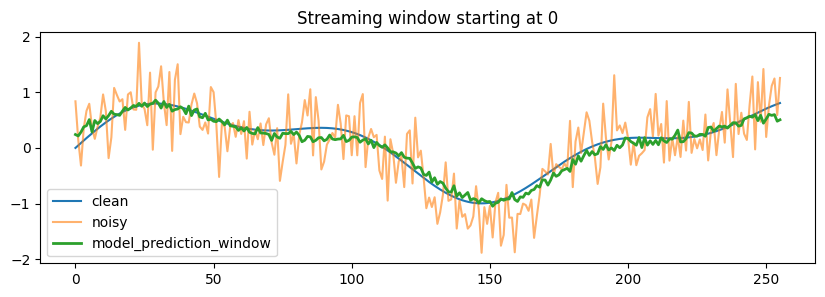

In [ ]:
# Cell 12 - Real-time-style streaming visualization (simulated)
import time
plt.ion()
fig, ax = plt.subplots(1,1,figsize=(10,3))
for start in range(0, len(noisy)-WINDOW, 50):  # step through signal
    seg_idx = start
    seg_clean = clean[seg_idx:seg_idx+WINDOW]
    seg_noisy = noisy[seg_idx:seg_idx+WINDOW]
    # prepare single-window input
    x_in = (seg_noisy / (np.max(np.abs(seg_noisy))+1e-12)).reshape(1,WINDOW,1).astype(np.float32)
    pred_win, _ = model.predict(x_in, verbose=0)
    pred_center = pred_win[0, WINDOW//2]
    # quick plot: center sample comparison across last few windows
    ax.clear()
    ax.plot(seg_clean, label='clean')
    ax.plot(seg_noisy, label='noisy', alpha=0.6)
    ax.plot(pred_win[0], label='model_prediction_window', lw=2)
    ax.set_title(f"Streaming window starting at {seg_idx}")
    ax.legend()
    plt.pause(0.08)
plt.ioff()



🔹 Testing on Linear Sine Mix signal...
LMS   : MSE=0.1835, SNR=2.90 dB
NLMS  : MSE=0.9987, SNR=0.68 dB
MODEL : MSE=0.0178, SNR=12.10 dB


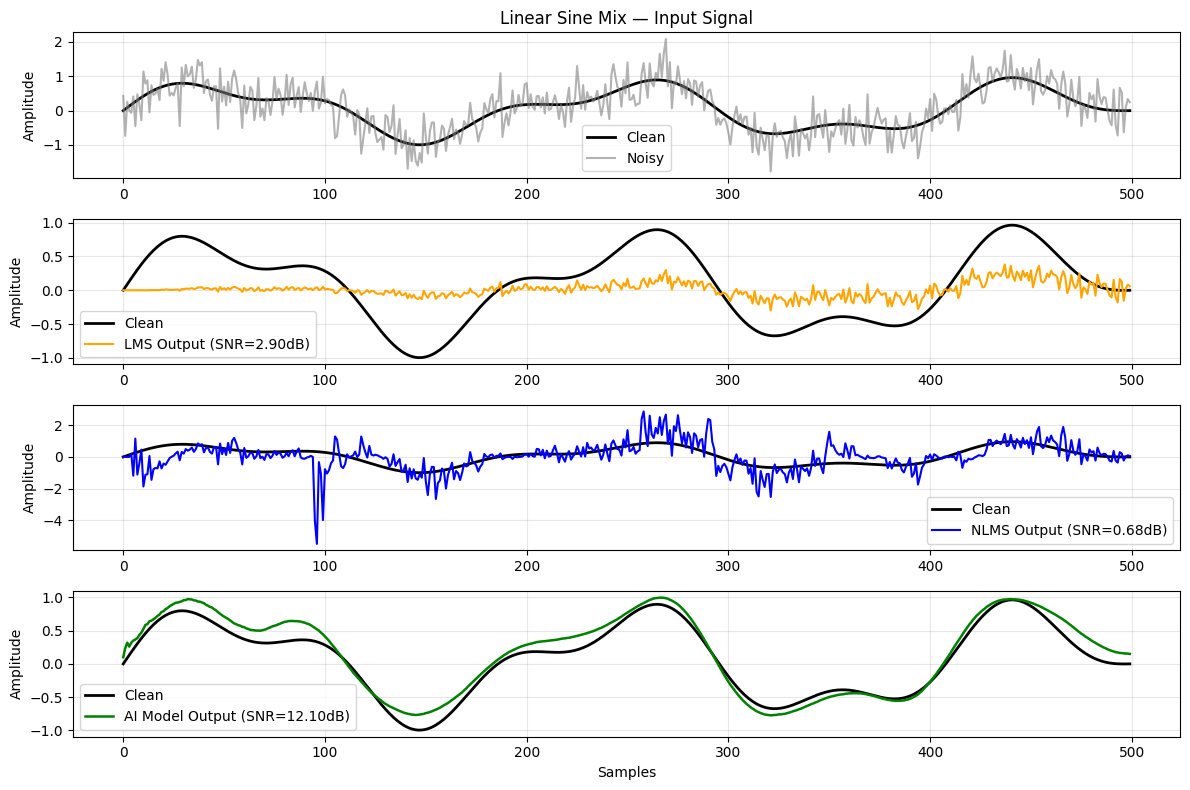


🔹 Testing on Square Wave signal...
LMS   : MSE=0.3263, SNR=2.95 dB
NLMS  : MSE=1.7243, SNR=0.65 dB
MODEL : MSE=0.1541, SNR=8.12 dB


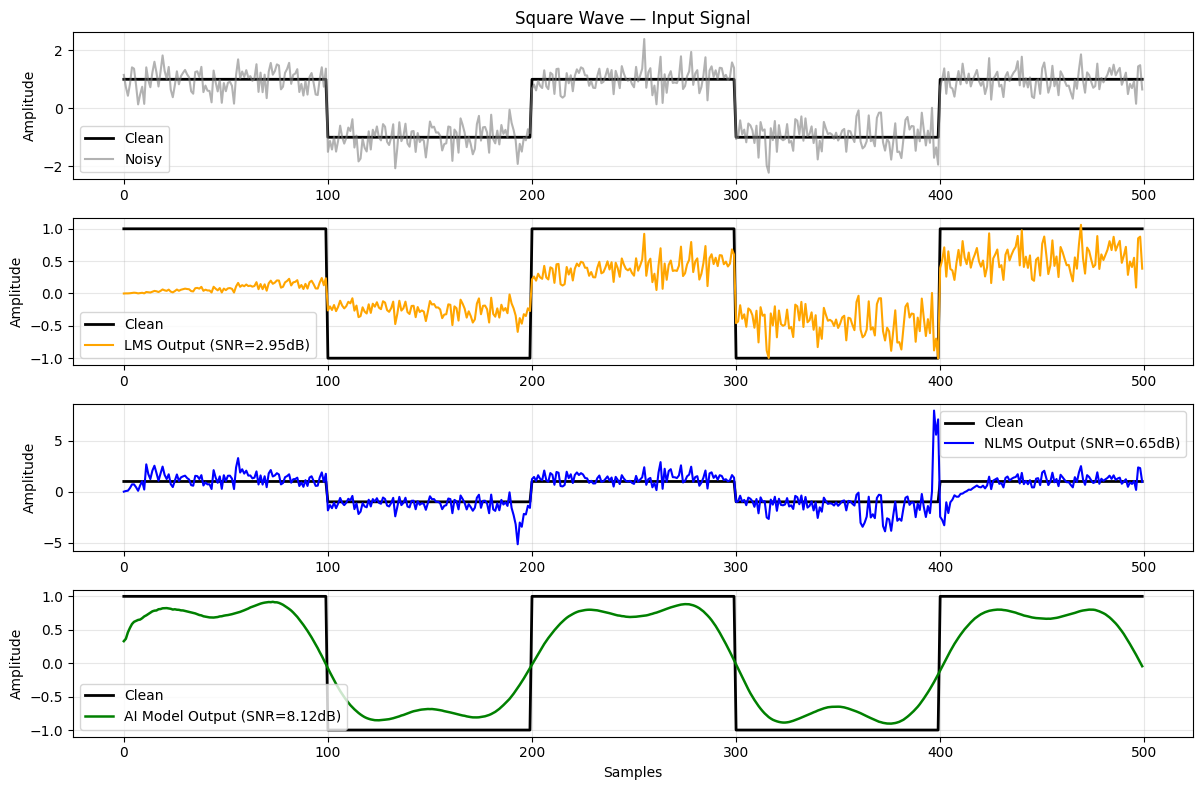


🔹 Testing on Sawtooth Wave signal...
LMS   : MSE=0.2057, SNR=2.26 dB
NLMS  : MSE=1.4096, SNR=1.12 dB
MODEL : MSE=0.0520, SNR=8.08 dB


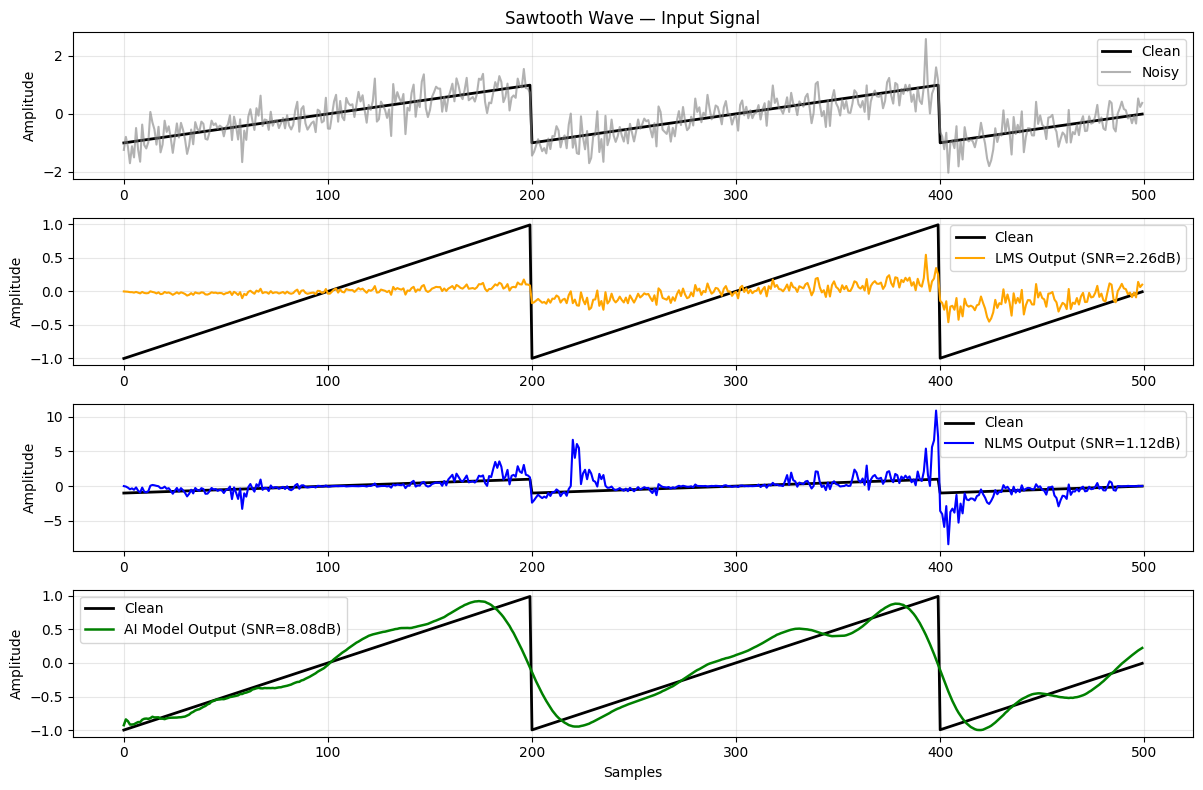


🔹 Testing on AM Modulated signal...
LMS   : MSE=0.2588, SNR=3.87 dB
NLMS  : MSE=1.0692, SNR=0.86 dB
MODEL : MSE=0.0124, SNR=16.57 dB


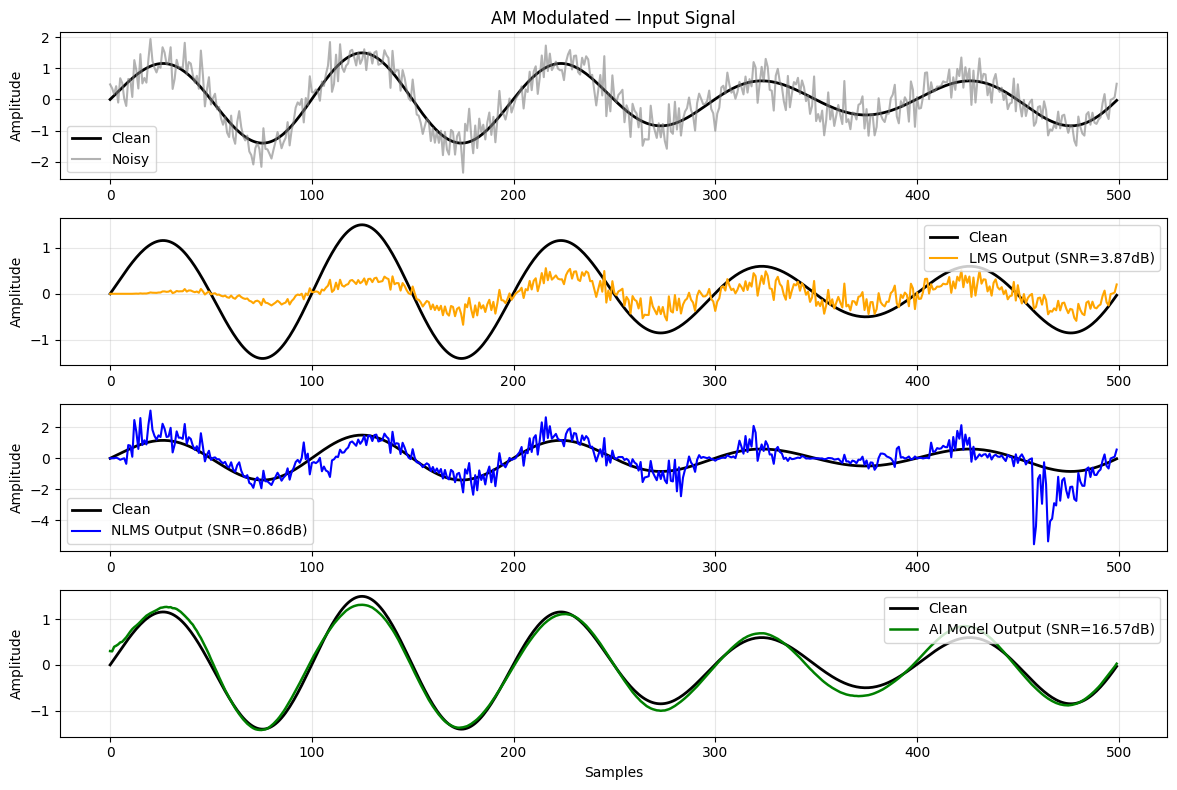


🔹 Testing on Nonlinear (Sine + Sine³) signal...
LMS   : MSE=0.3026, SNR=3.58 dB
NLMS  : MSE=1.7686, SNR=0.81 dB
MODEL : MSE=0.0212, SNR=15.51 dB


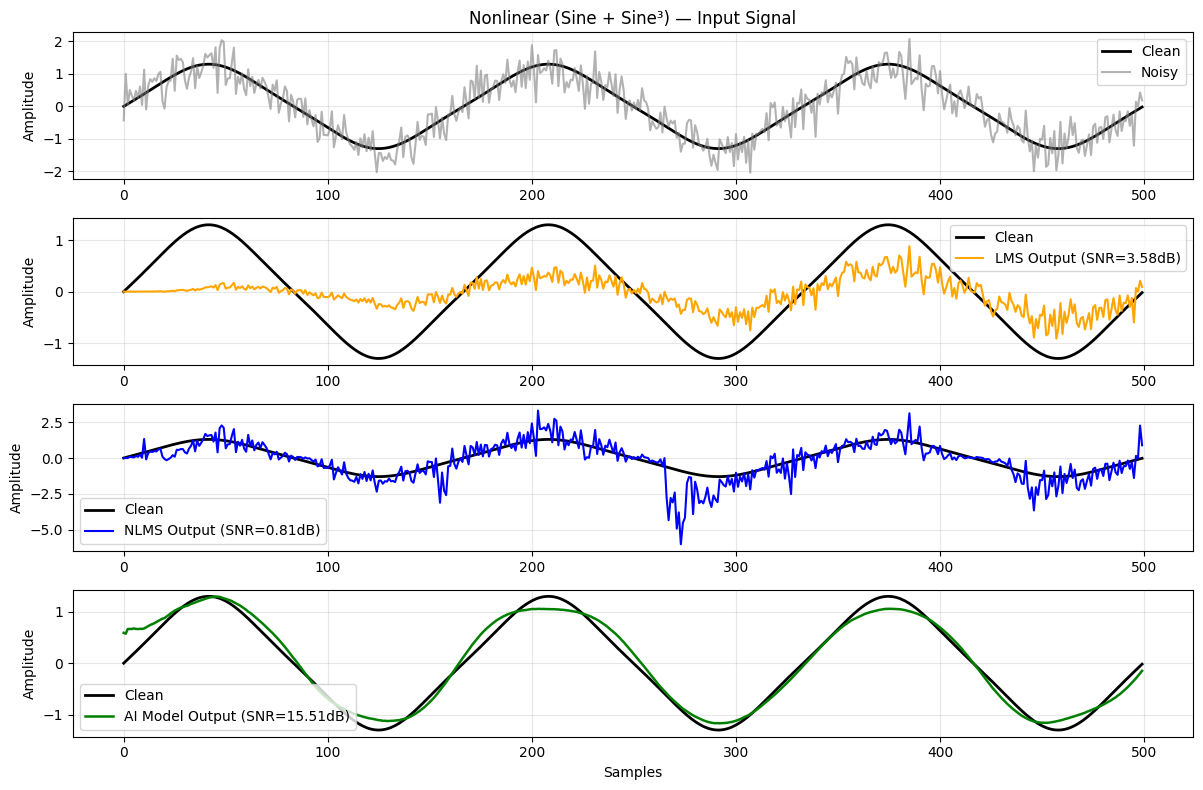

In [ ]:
# ===============================================================
# CELL 13 — MULTI-PANEL COMPARISON (CLEANLY SEPARATED SUBPLOTS)
# ===============================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from sklearn.metrics import mean_squared_error

# ------------------------------
# Helper functions
# ------------------------------
def snr_db(clean, processed):
    L = min(len(clean), len(processed))
    clean, processed = clean[:L], processed[:L]
    processed = processed * (np.max(np.abs(clean)) / (np.max(np.abs(processed)) + 1e-12))
    noise = clean - processed
    return 10*np.log10(np.mean(clean**2) / (np.mean(noise**2) + 1e-12))

def lms_filter(noisy, clean, mu=0.001):
    w = 0.0; yhat = np.zeros_like(noisy)
    for i in range(len(noisy)):
        yhat[i] = w * noisy[i]
        e = clean[i] - yhat[i]
        w += 2 * mu * e * noisy[i]
    return yhat

def nlms_filter(noisy, clean, mu=0.1, eps=1e-6):
    w = 0.0; yhat = np.zeros_like(noisy)
    for i in range(len(noisy)):
        denom = noisy[i]**2 + eps
        yhat[i] = w * noisy[i]
        e = clean[i] - yhat[i]
        w += (mu / denom) * e * noisy[i]
    return yhat

# ------------------------------
# Main testing function
# ------------------------------
def test_signal(clean, label="Sine+Noise"):
    print(f"\n🔹 Testing on {label} signal...")

    # Create noisy version
    noise = 0.4 * np.random.randn(len(clean))
    noisy = clean + noise

    # LMS & NLMS filtering
    y_lms = lms_filter(noisy, clean)
    y_nlms = nlms_filter(noisy, clean)

    # Prepare input for model
    noisy_norm = noisy / (np.max(np.abs(noisy)) + 1e-12)
    WINDOW = 256
    X_test = [noisy_norm[i:i+WINDOW].reshape(WINDOW,1) for i in range(len(noisy_norm)-WINDOW+1)]
    X_test = np.array(X_test, dtype=np.float32)

    # Predict with AI model
    y_pred, _ = model.predict(X_test, verbose=0)

    # Overlap-add reconstruction
    N = y_pred.shape[0]
    recon = np.zeros(N + WINDOW)
    count = np.zeros(N + WINDOW)
    for i in range(N):
        recon[i:i+WINDOW] += y_pred[i].reshape(-1)
        count[i:i+WINDOW] += 1
    y_model = recon / (count + 1e-12)
    y_model = y_model[:len(clean)]
    y_model = y_model * np.max(np.abs(clean)) / (np.max(np.abs(y_model)) + 1e-12)

    # --------------------------
    # Metrics
    # --------------------------
    mse_lms   = mean_squared_error(clean, y_lms)
    mse_nlms  = mean_squared_error(clean, y_nlms)
    mse_model = mean_squared_error(clean, y_model)

    snr_lms   = snr_db(clean, y_lms)
    snr_nlms  = snr_db(clean, y_nlms)
    snr_model = snr_db(clean, y_model)

    print(f"LMS   : MSE={mse_lms:.4f}, SNR={snr_lms:.2f} dB")
    print(f"NLMS  : MSE={mse_nlms:.4f}, SNR={snr_nlms:.2f} dB")
    print(f"MODEL : MSE={mse_model:.4f}, SNR={snr_model:.2f} dB")

    # --------------------------
    # Multi-panel plot
    # --------------------------
    plt.figure(figsize=(12, 8))
    n_show = 500  # first 500 samples

    plt.subplot(4,1,1)
    plt.plot(clean[:n_show], 'k', lw=2, label="Clean")
    plt.plot(noisy[:n_show], 'gray', alpha=0.6, label="Noisy")
    plt.title(f"{label} — Input Signal")
    plt.ylabel("Amplitude"); plt.legend(); plt.grid(True, alpha=0.3)

    plt.subplot(4,1,2)
    plt.plot(clean[:n_show], 'k', lw=2, label="Clean")
    plt.plot(y_lms[:n_show], 'orange', lw=1.5, label=f"LMS Output (SNR={snr_lms:.2f}dB)")
    plt.ylabel("Amplitude"); plt.legend(); plt.grid(True, alpha=0.3)

    plt.subplot(4,1,3)
    plt.plot(clean[:n_show], 'k', lw=2, label="Clean")
    plt.plot(y_nlms[:n_show], 'blue', lw=1.5, label=f"NLMS Output (SNR={snr_nlms:.2f}dB)")
    plt.ylabel("Amplitude"); plt.legend(); plt.grid(True, alpha=0.3)

    plt.subplot(4,1,4)
    plt.plot(clean[:n_show], 'k', lw=2, label="Clean")
    plt.plot(y_model[:n_show], 'green', lw=1.8, label=f"AI Model Output (SNR={snr_model:.2f}dB)")
    plt.ylabel("Amplitude"); plt.xlabel("Samples"); plt.legend(); plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

# ------------------------------
# Test with multiple signal types
# ------------------------------
fs = 1000
t = np.linspace(0, 1, fs)

signals = {
    "Linear Sine Mix": 0.7*np.sin(2*np.pi*5*t) + 0.3*np.sin(2*np.pi*12*t),
    "Square Wave": signal.square(2*np.pi*5*t),
    "Sawtooth Wave": signal.sawtooth(2*np.pi*5*t),
    "AM Modulated": (1 + 0.5*np.sin(2*np.pi*2*t)) * np.sin(2*np.pi*10*t),
    "Nonlinear (Sine + Sine³)": np.sin(2*np.pi*6*t) + 0.3*np.sin(2*np.pi*6*t)**3
}

for label, sig in signals.items():
    test_signal(sig, label)



🔹 Linear Sine Mix + Gaussian Noise
   LMS:   MSE=0.1922, SNR=2.52 dB
   NLMS:  MSE=1.3679, SNR=0.66 dB
   MODEL: MSE=0.0148, SNR=12.92 dB


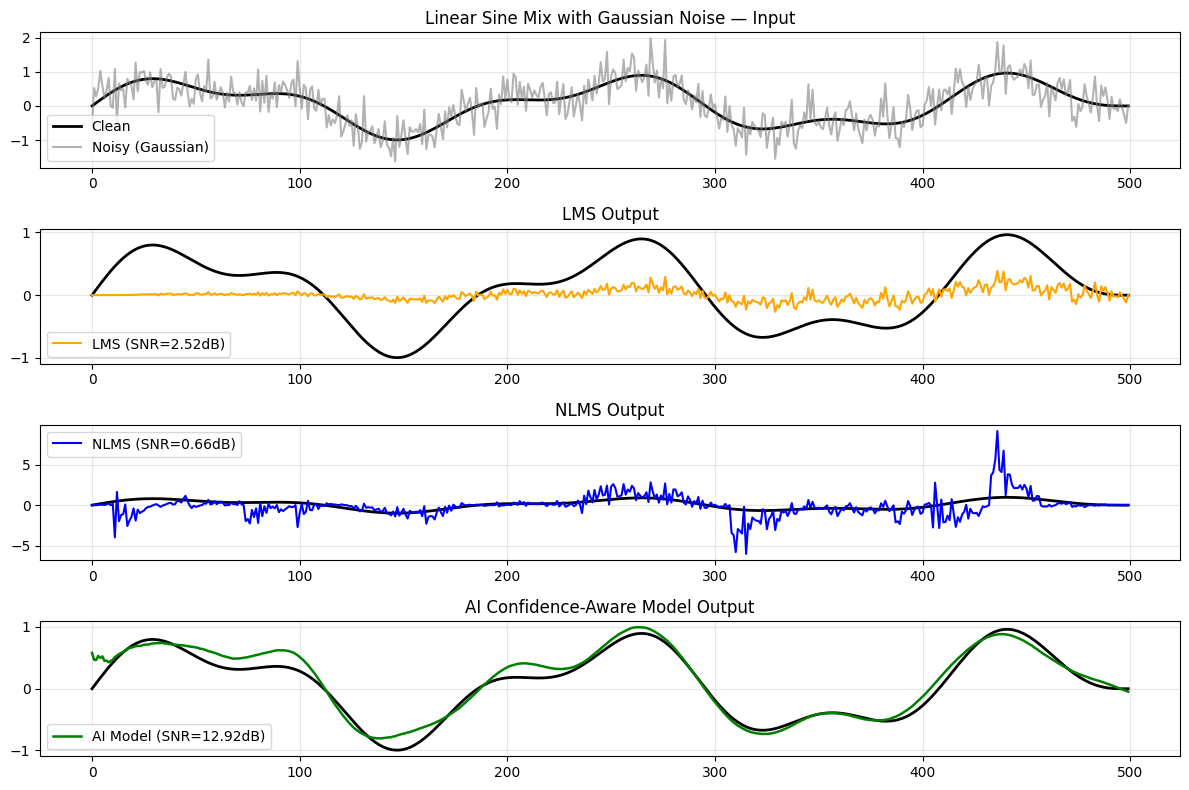


🔹 Linear Sine Mix + Impulse Noise
   LMS:   MSE=0.1725, SNR=3.39 dB
   NLMS:  MSE=0.0242, SNR=4.28 dB
   MODEL: MSE=0.0082, SNR=15.48 dB


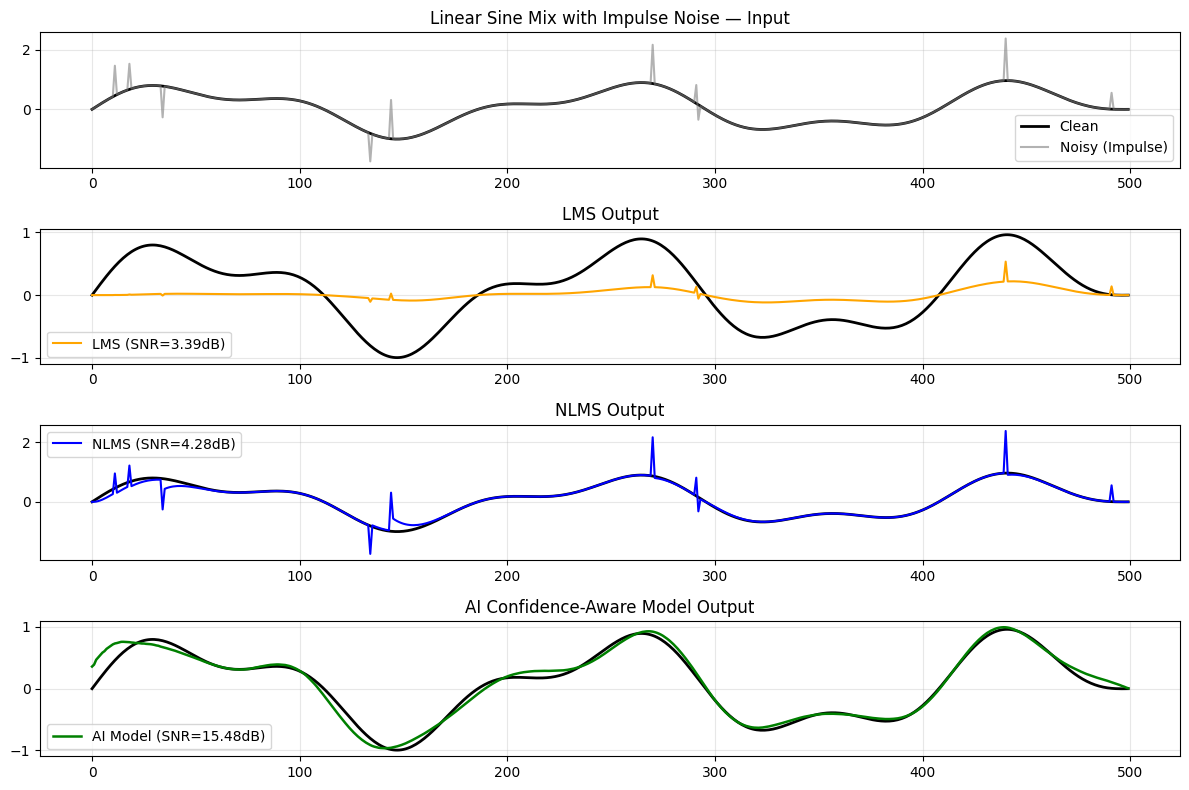


🔹 Linear Sine Mix + Sine Interference Noise
   LMS:   MSE=0.1773, SNR=4.46 dB
   NLMS:  MSE=0.3423, SNR=2.39 dB
   MODEL: MSE=0.0084, SNR=15.35 dB


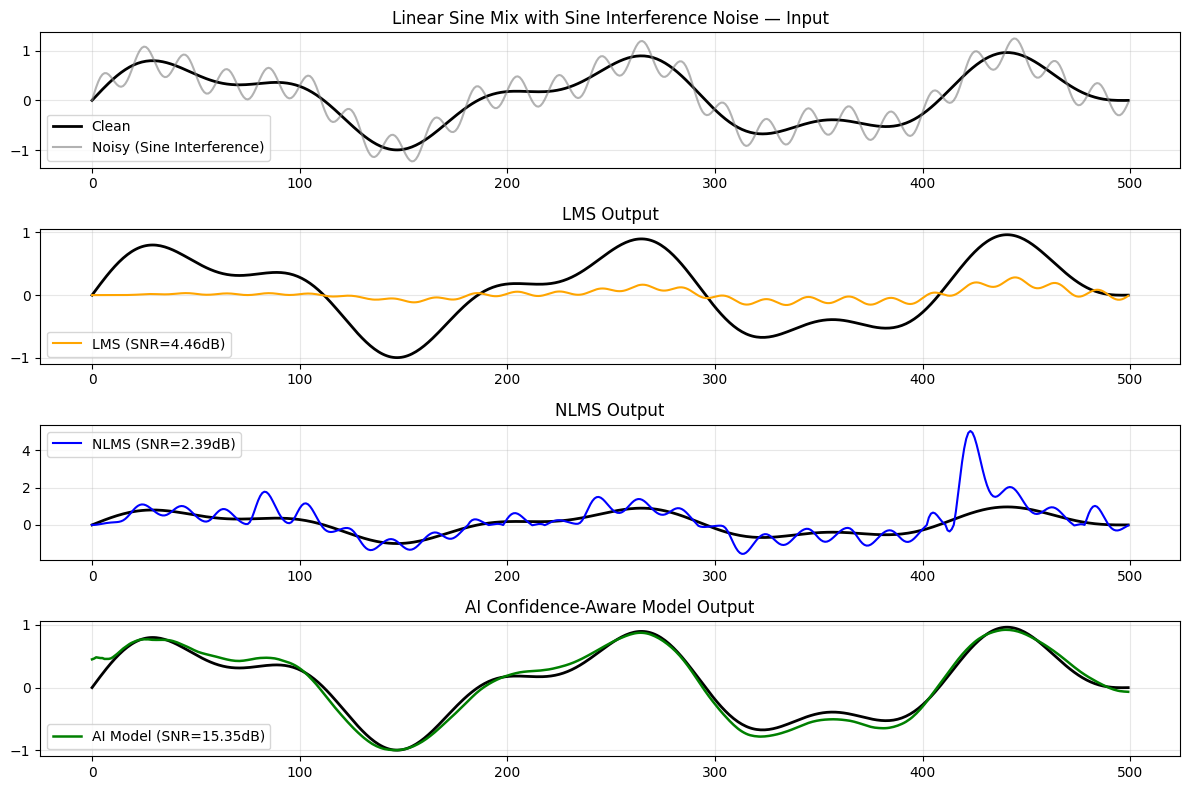


🔹 Linear Sine Mix + Brown Noise
   LMS:   MSE=0.1735, SNR=5.55 dB
   NLMS:  MSE=0.0057, SNR=14.00 dB
   MODEL: MSE=0.0213, SNR=11.34 dB


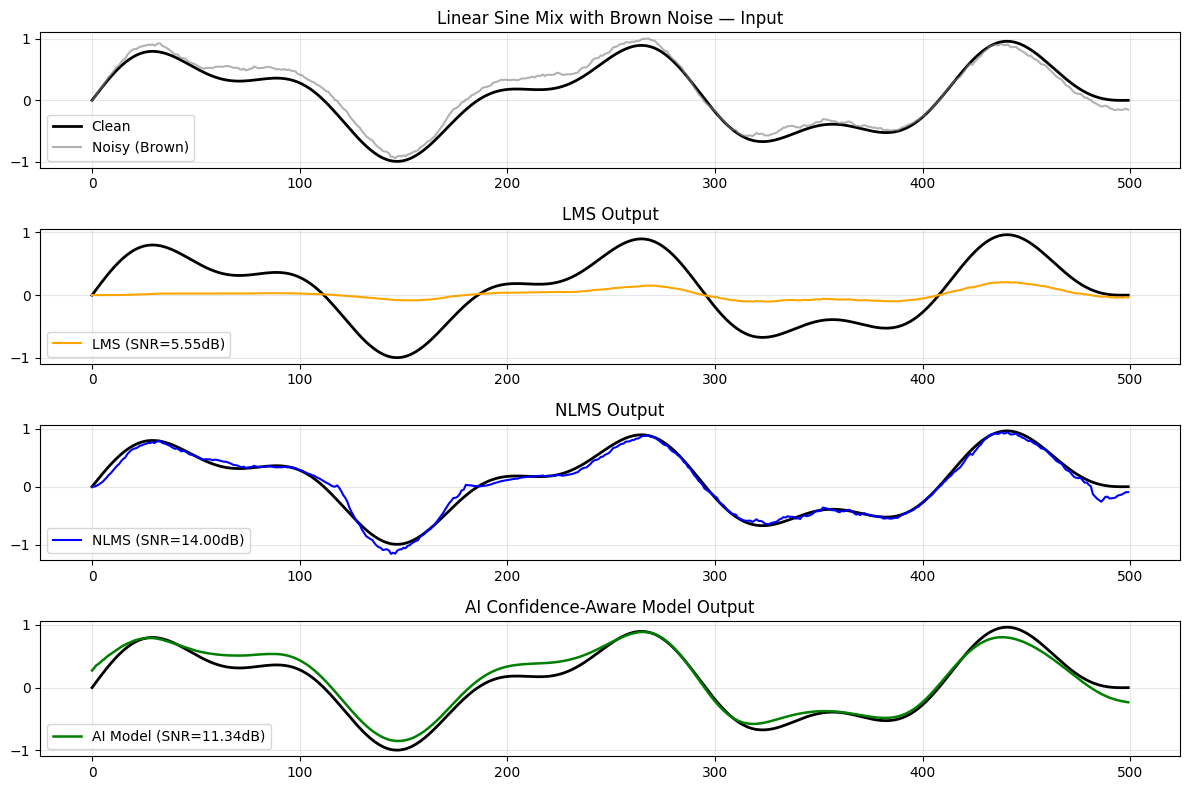

In [ ]:
# ===============================================================
# CELL 14 — TEST DIFFERENT NOISE TYPES (GAUSSIAN, IMPULSE, SINE, BROWN)
# ===============================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from sklearn.metrics import mean_squared_error

# ------------------------------
# Helper functions (reused)
# ------------------------------
def snr_db(clean, processed):
    L = min(len(clean), len(processed))
    clean, processed = clean[:L], processed[:L]
    processed = processed * (np.max(np.abs(clean)) / (np.max(np.abs(processed)) + 1e-12))
    noise = clean - processed
    return 10*np.log10(np.mean(clean**2) / (np.mean(noise**2) + 1e-12))

def lms_filter(noisy, clean, mu=0.001):
    w = 0.0; yhat = np.zeros_like(noisy)
    for i in range(len(noisy)):
        yhat[i] = w * noisy[i]
        e = clean[i] - yhat[i]
        w += 2 * mu * e * noisy[i]
    return yhat

def nlms_filter(noisy, clean, mu=0.1, eps=1e-6):
    w = 0.0; yhat = np.zeros_like(noisy)
    for i in range(len(noisy)):
        denom = noisy[i]**2 + eps
        yhat[i] = w * noisy[i]
        e = clean[i] - yhat[i]
        w += (mu / denom) * e * noisy[i]
    return yhat

# ------------------------------
# Generate various noise types
# ------------------------------
def generate_noisy_versions(clean):
    N = len(clean)
    noises = {}

    # 1. Gaussian noise
    noises["Gaussian"] = 0.4 * np.random.randn(N)

    # 2. Impulse noise (spikes)
    spikes = np.zeros(N)
    idx = np.random.randint(0, N, size=int(N*0.02))
    spikes[idx] = np.random.choice([-1, 1], len(idx)) * np.random.uniform(0.5, 1.5, len(idx))
    noises["Impulse"] = spikes

    # 3. Sine interference (e.g. 50Hz hum)
    noises["Sine Interference"] = 0.3 * np.sin(2*np.pi*50*np.linspace(0,1,N))

    # 4. Brown noise (low-frequency drift)
    white = np.random.randn(N)
    brown = np.cumsum(white)
    brown /= np.max(np.abs(brown))
    noises["Brown"] = 0.3 * brown

    return noises

# ------------------------------
# Main testing function for noise types
# ------------------------------
def test_different_noises(clean, label="Sine Mix"):
    noises = generate_noisy_versions(clean)
    WINDOW = 256

    for noise_type, noise in noises.items():
        noisy = clean + noise

        # Run baseline filters
        y_lms  = lms_filter(noisy, clean)
        y_nlms = nlms_filter(noisy, clean)

        # Model input
        noisy_norm = noisy / (np.max(np.abs(noisy)) + 1e-12)
        X_test = [noisy_norm[i:i+WINDOW].reshape(WINDOW,1) for i in range(len(noisy_norm)-WINDOW+1)]
        X_test = np.array(X_test, dtype=np.float32)

        y_pred, _ = model.predict(X_test, verbose=0)

        # Overlap-add reconstruction
        N = y_pred.shape[0]
        recon = np.zeros(N + WINDOW)
        count = np.zeros(N + WINDOW)
        for i in range(N):
            recon[i:i+WINDOW] += y_pred[i].reshape(-1)
            count[i:i+WINDOW] += 1
        y_model = recon / (count + 1e-12)
        y_model = y_model[:len(clean)]
        y_model = y_model * np.max(np.abs(clean)) / (np.max(np.abs(y_model)) + 1e-12)

        # Metrics
        snr_lms   = snr_db(clean, y_lms)
        snr_nlms  = snr_db(clean, y_nlms)
        snr_model = snr_db(clean, y_model)

        mse_lms   = mean_squared_error(clean, y_lms)
        mse_nlms  = mean_squared_error(clean, y_nlms)
        mse_model = mean_squared_error(clean, y_model)

        print(f"\n🔹 {label} + {noise_type} Noise")
        print(f"   LMS:   MSE={mse_lms:.4f}, SNR={snr_lms:.2f} dB")
        print(f"   NLMS:  MSE={mse_nlms:.4f}, SNR={snr_nlms:.2f} dB")
        print(f"   MODEL: MSE={mse_model:.4f}, SNR={snr_model:.2f} dB")

        # --------------------------
        # Subplots (4)
        # --------------------------
        plt.figure(figsize=(12,8))
        n_show = 500

        plt.subplot(4,1,1)
        plt.plot(clean[:n_show], 'k', lw=2, label="Clean")
        plt.plot(noisy[:n_show], 'gray', alpha=0.6, label=f"Noisy ({noise_type})")
        plt.title(f"{label} with {noise_type} Noise — Input"); plt.legend(); plt.grid(True, alpha=0.3)

        plt.subplot(4,1,2)
        plt.plot(clean[:n_show], 'k', lw=2)
        plt.plot(y_lms[:n_show], 'orange', lw=1.5, label=f"LMS (SNR={snr_lms:.2f}dB)")
        plt.title("LMS Output"); plt.legend(); plt.grid(True, alpha=0.3)

        plt.subplot(4,1,3)
        plt.plot(clean[:n_show], 'k', lw=2)
        plt.plot(y_nlms[:n_show], 'blue', lw=1.5, label=f"NLMS (SNR={snr_nlms:.2f}dB)")
        plt.title("NLMS Output"); plt.legend(); plt.grid(True, alpha=0.3)

        plt.subplot(4,1,4)
        plt.plot(clean[:n_show], 'k', lw=2)
        plt.plot(y_model[:n_show], 'green', lw=1.8, label=f"AI Model (SNR={snr_model:.2f}dB)")
        plt.title("AI Confidence-Aware Model Output"); plt.legend(); plt.grid(True, alpha=0.3)

        plt.tight_layout()
        plt.show()

# ------------------------------
# Run tests
# ------------------------------
fs = 1000
t = np.linspace(0, 1, fs)
clean_signal = 0.7*np.sin(2*np.pi*5*t) + 0.3*np.sin(2*np.pi*12*t)
test_different_noises(clean_signal, label="Linear Sine Mix")



🔹 Cubic Nonlinearity
   LMS   : MSE=0.3048, SNR=3.55 dB
   NLMS  : MSE=3.4619, SNR=0.47 dB
   MODEL : MSE=0.0208, SNR=15.57 dB


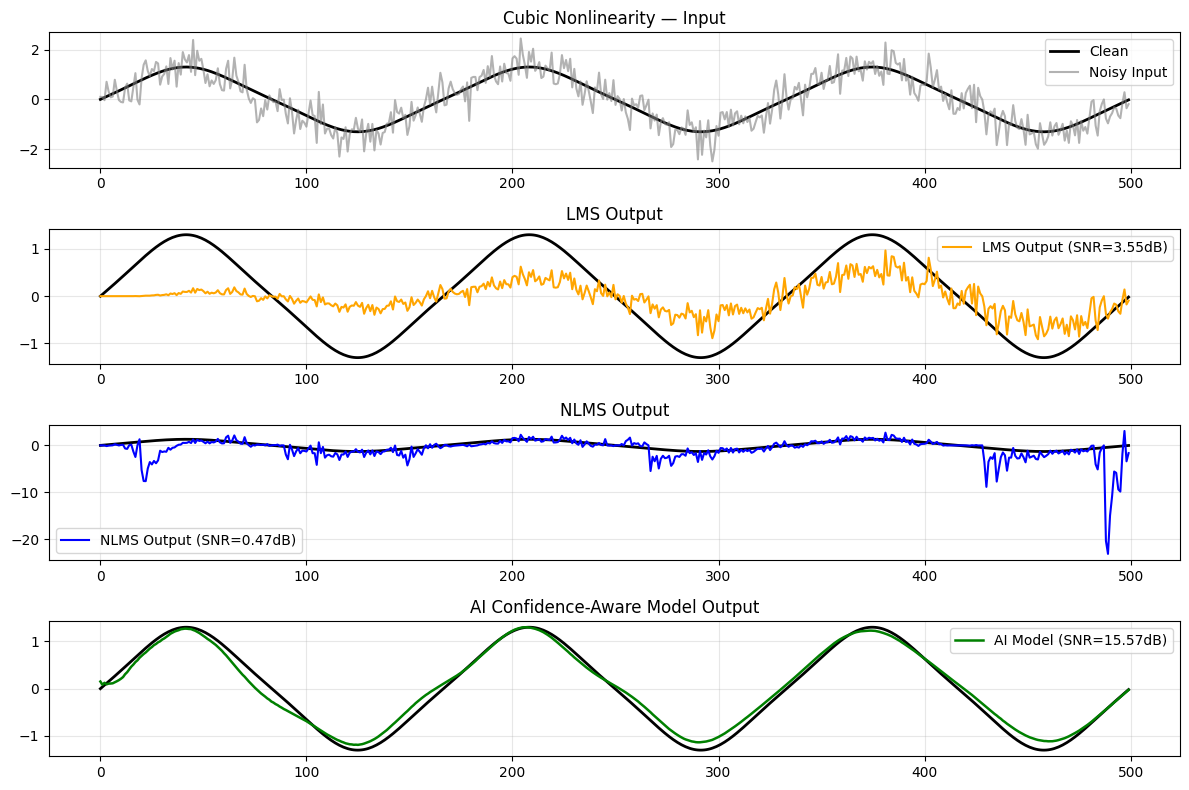


🔹 Amplitude Modulated Nonlinear
   LMS   : MSE=0.2169, SNR=2.91 dB
   NLMS  : MSE=1.0918, SNR=0.36 dB
   MODEL : MSE=0.0761, SNR=6.64 dB


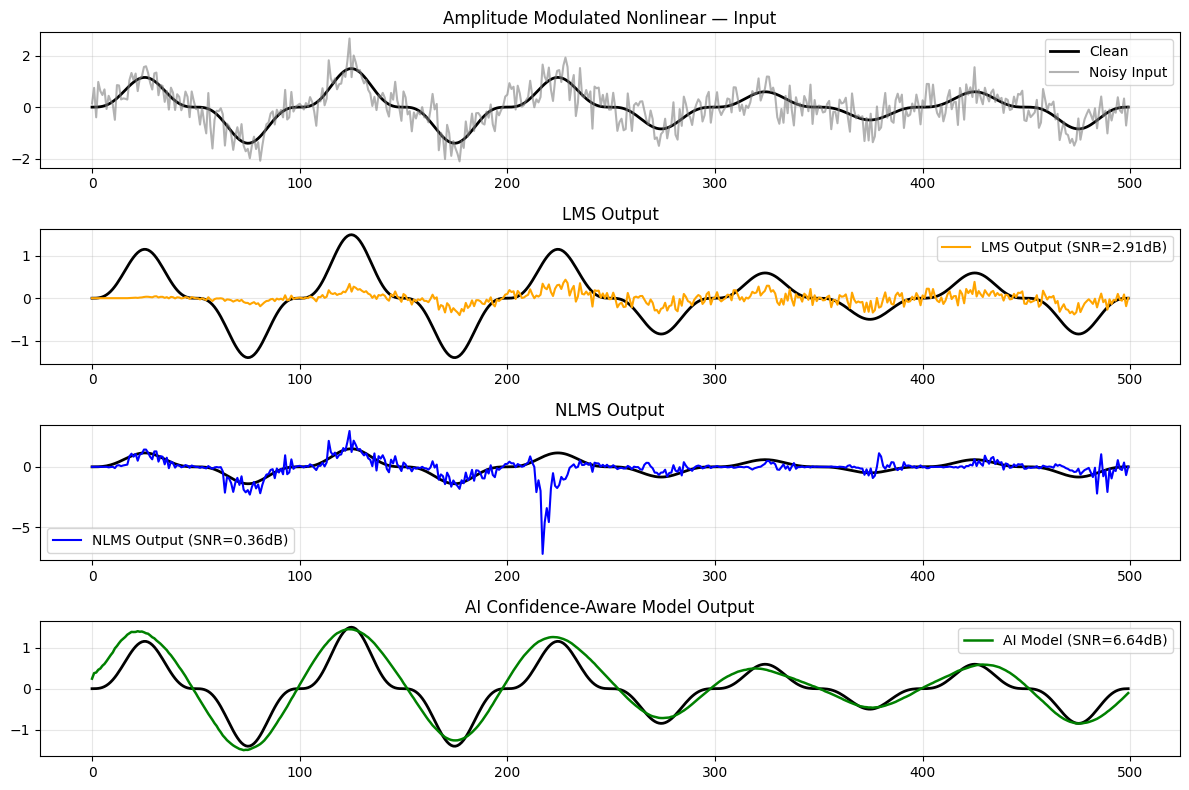


🔹 Chaotic-like Nonlinear
   LMS   : MSE=0.2206, SNR=2.14 dB
   NLMS  : MSE=2.0371, SNR=0.37 dB
   MODEL : MSE=0.0285, SNR=10.79 dB


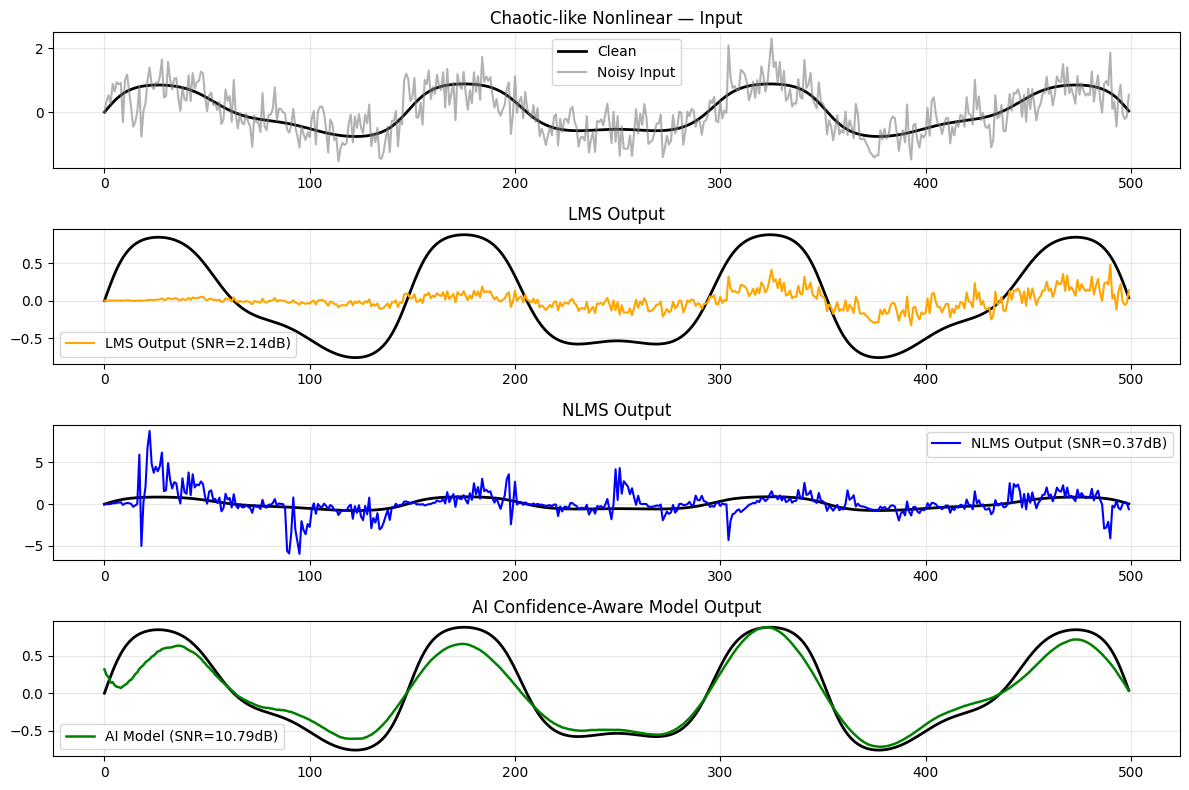

In [ ]:
# ===============================================================
# CELL 15 — NONLINEAR SIGNAL TESTING
# ===============================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from sklearn.metrics import mean_squared_error

# ------------------------------
# Helper Functions (same as before)
# ------------------------------
def snr_db(clean, processed):
    L = min(len(clean), len(processed))
    clean, processed = clean[:L], processed[:L]
    processed = processed * (np.max(np.abs(clean)) / (np.max(np.abs(processed)) + 1e-12))
    noise = clean - processed
    return 10*np.log10(np.mean(clean**2) / (np.mean(noise**2) + 1e-12))

def lms_filter(noisy, clean, mu=0.001):
    w = 0.0; yhat = np.zeros_like(noisy)
    for i in range(len(noisy)):
        yhat[i] = w * noisy[i]
        e = clean[i] - yhat[i]
        w += 2 * mu * e * noisy[i]
    return yhat

def nlms_filter(noisy, clean, mu=0.1, eps=1e-6):
    w = 0.0; yhat = np.zeros_like(noisy)
    for i in range(len(noisy)):
        denom = noisy[i]**2 + eps
        yhat[i] = w * noisy[i]
        e = clean[i] - yhat[i]
        w += (mu / denom) * e * noisy[i]
    return yhat

# ------------------------------
# Nonlinear Test Function
# ------------------------------
def test_nonlinear_signal(clean, label="Nonlinear Signal"):
    # Generate mixed noise types
    N = len(clean)
    noise_gaussian = 0.4 * np.random.randn(N)
    noise_sine = 0.3 * np.sin(2*np.pi*50*np.linspace(0,1,N))
    noise_impulse = np.zeros(N)
    idx = np.random.randint(0, N, int(N*0.02))
    noise_impulse[idx] = np.random.choice([-1, 1], len(idx)) * np.random.uniform(0.5, 1.0, len(idx))

    # Combined nonlinear noise
    noise = noise_gaussian + noise_sine + noise_impulse
    noisy = clean + noise

    # Apply LMS and NLMS
    y_lms  = lms_filter(noisy, clean)
    y_nlms = nlms_filter(noisy, clean)

    # Apply your model
    WINDOW = 256
    noisy_norm = noisy / (np.max(np.abs(noisy)) + 1e-12)
    X_test = [noisy_norm[i:i+WINDOW].reshape(WINDOW,1) for i in range(len(noisy_norm)-WINDOW+1)]
    X_test = np.array(X_test, dtype=np.float32)

    y_pred, _ = model.predict(X_test, verbose=0)

    # Reconstruct full signal via overlap-add
    N = y_pred.shape[0]
    recon = np.zeros(N + WINDOW)
    count = np.zeros(N + WINDOW)
    for i in range(N):
        recon[i:i+WINDOW] += y_pred[i].reshape(-1)
        count[i:i+WINDOW] += 1
    y_model = recon / (count + 1e-12)
    y_model = y_model[:len(clean)]
    y_model = y_model * np.max(np.abs(clean)) / (np.max(np.abs(y_model)) + 1e-12)

    # Metrics
    mse_lms   = mean_squared_error(clean, y_lms)
    mse_nlms  = mean_squared_error(clean, y_nlms)
    mse_model = mean_squared_error(clean, y_model)

    snr_lms   = snr_db(clean, y_lms)
    snr_nlms  = snr_db(clean, y_nlms)
    snr_model = snr_db(clean, y_model)

    print(f"\n🔹 {label}")
    print(f"   LMS   : MSE={mse_lms:.4f}, SNR={snr_lms:.2f} dB")
    print(f"   NLMS  : MSE={mse_nlms:.4f}, SNR={snr_nlms:.2f} dB")
    print(f"   MODEL : MSE={mse_model:.4f}, SNR={snr_model:.2f} dB")

    # --------------------------
    # Subplots (4)
    # --------------------------
    plt.figure(figsize=(12,8))
    n_show = 500

    plt.subplot(4,1,1)
    plt.plot(clean[:n_show], 'k', lw=2, label="Clean")
    plt.plot(noisy[:n_show], 'gray', alpha=0.6, label="Noisy Input")
    plt.title(f"{label} — Input"); plt.legend(); plt.grid(True, alpha=0.3)

    plt.subplot(4,1,2)
    plt.plot(clean[:n_show], 'k', lw=2)
    plt.plot(y_lms[:n_show], 'orange', lw=1.5, label=f"LMS Output (SNR={snr_lms:.2f}dB)")
    plt.title("LMS Output"); plt.legend(); plt.grid(True, alpha=0.3)

    plt.subplot(4,1,3)
    plt.plot(clean[:n_show], 'k', lw=2)
    plt.plot(y_nlms[:n_show], 'blue', lw=1.5, label=f"NLMS Output (SNR={snr_nlms:.2f}dB)")
    plt.title("NLMS Output"); plt.legend(); plt.grid(True, alpha=0.3)

    plt.subplot(4,1,4)
    plt.plot(clean[:n_show], 'k', lw=2)
    plt.plot(y_model[:n_show], 'green', lw=1.8, label=f"AI Model (SNR={snr_model:.2f}dB)")
    plt.title("AI Confidence-Aware Model Output"); plt.legend(); plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

# ------------------------------
# Run Nonlinear Signal Tests
# ------------------------------
fs = 1000
t = np.linspace(0, 1, fs)

nonlinear_signals = {
    "Cubic Nonlinearity": np.sin(2*np.pi*6*t) + 0.3*(np.sin(2*np.pi*6*t))**3,
    "Amplitude Modulated Nonlinear": (1 + 0.5*np.sin(2*np.pi*2*t)) * np.sin(2*np.pi*10*t)**3,
    "Chaotic-like Nonlinear": np.tanh(np.sin(2*np.pi*7*t) + 0.4*np.sin(2*np.pi*13*t))
}

for label, sig in nonlinear_signals.items():
    test_nonlinear_signal(sig, label)


Upwards are just for evaluation

In [ ]:
# Cell 13 - Example: run inference with the float TFLite model
import numpy as np, tensorflow as tf
tflite_path = tflite_fname  # from earlier
interpreter = tf.lite.Interpreter(model_path=tflite_path)
interpreter.allocate_tensors()
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()
print("TFLite input:", input_details, "output:", output_details)

# run single-window inference example
test_win = noisy[100:100+WINDOW]
test_win_norm = (test_win / (np.max(np.abs(test_win))+1e-12)).astype(np.float32).reshape(1,WINDOW,1)
interpreter.set_tensor(input_details[0]['index'], test_win_norm)
interpreter.invoke()
out = interpreter.get_tensor(output_details[0]['index'])  # reg_out
print("TFLite reg_out shape:", out.shape)


TFLite input: [{'name': 'serving_default_keras_tensor:0', 'index': 0, 'shape': array([  1, 256,   1], dtype=int32), 'shape_signature': array([ -1, 256,   1], dtype=int32), 'dtype': <class 'numpy.float32'>, 'quantization': (0.0, 0), 'quantization_parameters': {'scales': array([], dtype=float32), 'zero_points': array([], dtype=int32), 'quantized_dimension': 0}, 'sparsity_parameters': {}}] output: [{'name': 'StatefulPartitionedCall_1:1', 'index': 34, 'shape': array([1, 1], dtype=int32), 'shape_signature': array([-1,  1], dtype=int32), 'dtype': <class 'numpy.float32'>, 'quantization': (0.0, 0), 'quantization_parameters': {'scales': array([], dtype=float32), 'zero_points': array([], dtype=int32), 'quantized_dimension': 0}, 'sparsity_parameters': {}}, {'name': 'StatefulPartitionedCall_1:0', 'index': 35, 'shape': array([  1, 256], dtype=int32), 'shape_signature': array([ -1, 256], dtype=int32), 'dtype': <class 'numpy.float32'>, 'quantization': (0.0, 0), 'quantization_parameters': {'scales': a

/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [ ]:
# Cell 13 - Quick README / talking points to present
print("""
Presentation checklist:
1) Dataset: Kaggle IoT + Modulation + synthetic windows -> >=6000 windows.
2) Model: small 1D-CNN dual-head -> regression (window) + classification (signal/noise).
3) Novelty: confidence-aware online fine-tuning (use classifier confidence to scale online learning rate), and dual-task (classify then denoise).
4) Baselines: LMS & NLMS (center-sample) compared numerically (MSE, SNR) and with streaming plots.
5) Deployment: model saved and converted to TFLite; quantized variant attempted.
6) Demo: Use streaming plot cell to show real-time-like behavior; load saved .tflite on a Pi for edge.
""")



Presentation checklist:
1) Dataset: Kaggle IoT + Modulation + synthetic windows -> >=6000 windows.
2) Model: small 1D-CNN dual-head -> regression (window) + classification (signal/noise).
3) Novelty: confidence-aware online fine-tuning (use classifier confidence to scale online learning rate), and dual-task (classify then denoise).
4) Baselines: LMS & NLMS (center-sample) compared numerically (MSE, SNR) and with streaming plots.
5) Deployment: model saved and converted to TFLite; quantized variant attempted.
6) Demo: Use streaming plot cell to show real-time-like behavior; load saved .tflite on a Pi for edge.



✅ Loaded trained model: confidence_model_1762251955.h5
✅ Input shape for model: (744, 256, 1)
✅ Output range: 0.0 to 0.2958787329300808

==== COMPARISON (offline trained model) ====
LMS    : MSE = 0.19019,  SNR = 2.77 dB
NLMS   : MSE = 1.57100,  SNR = 0.21 dB
MODEL  : MSE = 0.33675,  SNR = -3.37 dB


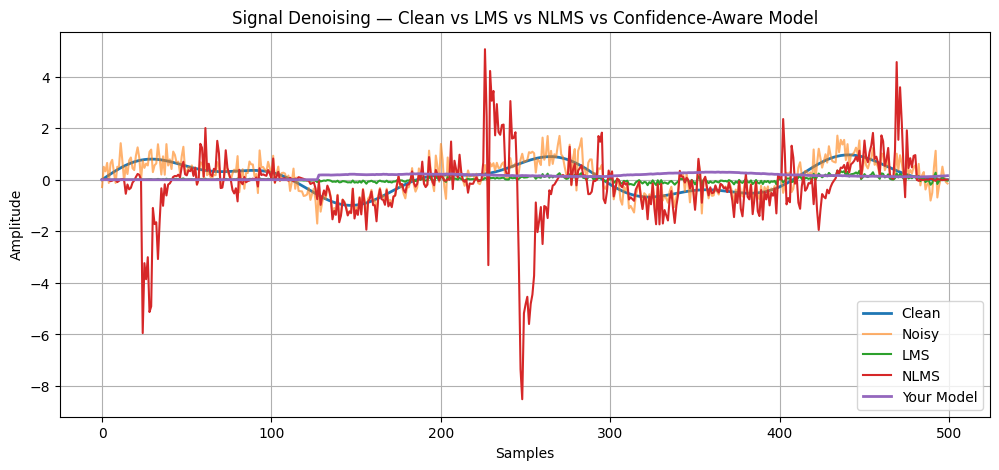

noisy shape: (1000,)
clean shape: (1000,)
X_new shape (windows): (744, 256, 1)
y_pred shape: (744, 256)
y_pred min/max: -0.23378062 0.6046421
clean min/max: -0.9957197498624528 0.995719749862453


In [ ]:
import numpy as np

# list all array-like objects in the current namespace
candidates = {name: obj for name, obj in globals().items()
              if isinstance(obj, (np.ndarray, list))}

print("Candidate array-like variables and their shapes/lengths:\n")
for name, arr in sorted(candidates.items()):
    try:
        shape = getattr(arr, 'shape', None)
        if shape is None:
            length = len(arr)
            print(f"{name:20s}  length={length}")
        else:
            print(f"{name:20s}  shape={shape}")
    except Exception as e:
        print(f"{name:20s}  (unreadable: {e})")


Candidate array-like variables and their shapes/lengths:

In                    length=14
X_windows             shape=(6000, 256)
X_windows_norm        shape=(6000, 256)
Xte                   shape=(720, 256, 1)
Xtr                   shape=(5280, 256, 1)
Y_clean               shape=(6000, 256)
Y_clean_norm          shape=(6000, 256)
Y_label               shape=(6000,)
Yc_te                 shape=(720, 1)
Yc_tr                 shape=(5280, 1)
Yr_te                 shape=(720, 256)
Yr_tr                 shape=(5280, 256)
_dh                   length=1
_ih                   length=14
ecg                   shape=(50000,)
s                     shape=(50000,)
sources               length=4
t                     shape=(50000,)
w                     shape=(256,)
win_clean             shape=(256,)
win_noisy             shape=(256,)
x_win                 shape=(1, 256, 1)
